# Model Comparison

Side-by-side comparison of all trained models on **validation data**.  
Sections: validation summary · PR/ROC curves · **subclass recall** (key metric) · confusion matrices.  
Test-set results appear only in the final section to avoid influencing model selection.

In [1]:
import json
import os
import sys
import tempfile
from pathlib import Path


def find_project_root(start=None):
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'pyproject.toml').exists() and (candidate / 'outputs').exists():
            return candidate
    fallback = Path('/Users/jaumemalenacortes/Desktop/AABI/AAIB')
    return fallback if fallback.exists() else start


PROJECT_ROOT = find_project_root()
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'matplotlib-aaib'))
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(obj)

from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve, average_precision_score,
    confusion_matrix,
)
from kvasir_triage.data.labels import BINARY_LABEL

RUNS_ROOT      = PROJECT_ROOT / 'outputs' / 'runs'
TEST_EVAL_ROOT = PROJECT_ROOT / 'outputs' / 'test_evaluation'

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

# ── MODEL REGISTRY ──────────────────────────────────────────────────────────
MODELS = [
    {'config': 'efficientnet_b0', 'name': 'EfficientNet-B0', 'short': 'EffB0', 'color': '#1565C0'},
    {'config': 'efficientnet_v2_s', 'name': 'EfficientNet-V2-S', 'short': 'EffV2-S', 'color': '#2e7d32'},
    {'config': 'efficientnet_v2_m', 'name': 'EfficientNet-V2-M', 'short': 'EffV2-M', 'color': '#e65100'},
    {'config': 'efficientnet_v2_l', 'name': 'EfficientNet-V2-L', 'short': 'EffV2-L', 'color': '#6a1b9a'},
    {'config': 'mobilenet_v3_large', 'name': 'MobileNet-V3-Large', 'short': 'MobV3-L', 'color': '#00838f'},
    {'config': 'densenet161_pretrained', 'name': 'DenseNet-161 (pretrained)', 'short': 'DN161-pre', 'color': '#c62828'},
]

SUSPICIOUS_CLASSES = ['Angiectasia', 'Erosion', 'Erythema', 'Foreign body', 'Lymphangiectasia', 'Ulcer']

print(f'PROJECT_ROOT : {PROJECT_ROOT}')
print(f'RUNS_ROOT    : {RUNS_ROOT}  (exists={RUNS_ROOT.exists()})')

PROJECT_ROOT : D:\Git\AAIB
RUNS_ROOT    : D:\Git\AAIB\outputs\runs  (exists=True)


In [2]:
# ── HELPER FUNCTIONS ────────────────────────────────────────────────────────

def find_run(config_name):
    for pattern in (f'{config_name}_fold0_*', f'{config_name}_*'):
        candidates = sorted(
            [p for p in RUNS_ROOT.glob(pattern) if p.is_dir()],
            key=lambda p: p.stat().st_mtime,
        )
        if candidates:
            return candidates[-1]
    return None


def load_metrics(run_dir):
    path = run_dir / 'metrics.jsonl'
    if not path.exists():
        return pd.DataFrame()
    rows = []
    with open(path) as f:
        for line in f:
            s = line.strip()
            if s:
                rows.append(json.loads(s))
    return pd.DataFrame(rows).replace({None: float('nan')})


def load_val_preds(run_dir):
    """Returns (logits, labels, subclasses) or None."""
    for fname in ('eval_predictions_val.npz', 'val_preds_best.npz'):
        p = run_dir / fname
        if not p.exists():
            continue
        d      = np.load(p, allow_pickle=True)
        logits = d['logits']
        labels = d['true_labels'] if 'true_labels' in d.files else d['labels']
        subs   = d['subclasses'].astype(str)
        if logits.ndim == 2 and logits.shape[1] == 1:
            logits = logits[:, 0]
        return logits, labels, subs
    return None


def load_threshold_cal(run_dir):
    p = run_dir / 'threshold_calibration.json'
    return json.loads(p.read_text()) if p.exists() else {}


def load_test_results(config_name):
    exact = TEST_EVAL_ROOT / f'{config_name}_test_results.json'
    if exact.exists():
        return json.loads(exact.read_text())

    matches = sorted(
        TEST_EVAL_ROOT.glob(f'{config_name}*_test_results.json'),
        key=lambda p: p.stat().st_mtime,
    )
    return json.loads(matches[-1].read_text()) if matches else None


def subclass_recall_at_t(logits, labels, subclasses, threshold):
    """Per-suspicious-class recall at a given decision threshold."""
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= threshold).astype(int)
    out = {}
    for sub in SUSPICIOUS_CLASSES:
        mask = subclasses == sub
        if not mask.any():
            continue
        y_t = labels[mask]
        y_p = preds[mask]
        tp  = int(((y_p == 1) & (y_t == 1)).sum())
        fn  = int(((y_p == 0) & (y_t == 1)).sum())
        out[sub] = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    return out


def _f(x):
    """None-safe float."""
    return float('nan') if x is None else float(x)

In [3]:
# ── LOAD ALL MODELS ──────────────────────────────────────────────────────────
MODEL_DATA = {}

for m in MODELS:
    cfg   = m['config']
    rd    = find_run(cfg)
    cal   = load_threshold_cal(rd) if rd else {}
    df_m  = load_metrics(rd)       if rd else pd.DataFrame()
    preds = load_val_preds(rd)     if rd else None
    test  = load_test_results(cfg)

    # Best-epoch validation metrics (from metrics.jsonl)
    best_epoch = None
    val_prauc = val_mcc = val_npv = float('nan')
    if not df_m.empty and 'val_pr_auc' in df_m.columns:
        best_idx   = df_m['val_pr_auc'].idxmax()
        best_epoch = int(df_m.loc[best_idx, 'epoch'])
        val_prauc  = _f(df_m.loc[best_idx].get('val_pr_auc'))
        val_mcc    = _f(df_m.loc[best_idx].get('val_mcc'))
        val_npv    = _f(df_m.loc[best_idx].get('val_npv'))

    # Prefer calibration-JSON values (computed by evaluate.py on full val set)
    if cal:
        val_prauc = _f(cal.get('pr_auc', val_prauc))
        val_mcc   = _f(cal.get('mcc',    val_mcc))
        val_npv   = _f(cal.get('npv',    val_npv))

    t_cal    = cal.get('threshold')
    sub_r05  = cal.get('subclass_recall', {})   # recall per suspicious class at t=0.5
    sub_rcal = {}                                # recall per class at calibrated threshold
    if preds is not None and t_cal is not None:
        sub_rcal = subclass_recall_at_t(preds[0], preds[1], preds[2], t_cal)

    MODEL_DATA[cfg] = {
        'name':          m['name'],
        'short':         m['short'],
        'color':         m['color'],
        'run_dir':       rd,
        'run_found':     rd is not None,
        'best_epoch':    best_epoch,
        'val_prauc':     val_prauc,
        'val_mcc':       val_mcc,
        'val_npv':       val_npv,
        'recall_tcal':   _f(cal.get('recall')),
        'prec_tcal':     _f(cal.get('precision')),
        'threshold_cal': t_cal,
        'cal_status':    cal.get('status', '\u2014'),
        'sub_r05':       sub_r05,
        'sub_rcal':      sub_rcal,
        'val_preds':     preds,
        'df_metrics':    df_m,
        'test':          test,
    }

    prauc_str = f'PR-AUC={val_prauc:.4f}' if not np.isnan(val_prauc) else 'PR-AUC=N/A (no run)'
    run_str   = rd.name if rd else 'NO RUN'
    print(f'  {m["name"]:35s}  {run_str:40s}  {prauc_str}')

print('\nAll models loaded.')

  EfficientNet-B0                      efficientnet_b0_full_fold0                PR-AUC=0.7403
  EfficientNet-V2-S                    efficientnet_v2_s_full_fold0              PR-AUC=0.7873
  EfficientNet-V2-M                    efficientnet_v2_m_full_fold0              PR-AUC=0.8273
  EfficientNet-V2-L                    efficientnet_v2_l_full_fold0              PR-AUC=0.7961
  MobileNet-V3-Large                   mobilenet_v3_large_full_fold0             PR-AUC=0.6912
  DenseNet-161 (pretrained)            densenet161_pretrained_full_fold0         PR-AUC=0.7471

All models loaded.


C:\Users\jordi\AppData\Local\Temp\ipykernel_19828\3608351286.py:62: RuntimeWarning: overflow encountered in exp
  probs = 1 / (1 + np.exp(-logits))
C:\Users\jordi\AppData\Local\Temp\ipykernel_19828\3608351286.py:62: RuntimeWarning: overflow encountered in exp
  probs = 1 / (1 + np.exp(-logits))


---
## 1 · Validation Summary

All metrics from the **validation split** (no test data used here).  
- **PR-AUC / MCC / NPV** are at the default threshold *t = 0.5*.  
- **Recall@t_cal / Prec@t_cal** are at the threshold calibrated to achieve ≥ 90 % recall.

In [4]:
# ── SUMMARY TABLE ───────────────────────────────────────────────────────────
def _fmt(v, decimals=4):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return '\u2014'
    return round(float(v), decimals)


rows = []
for m in MODELS:
    d = MODEL_DATA[m['config']]
    rows.append({
        'Model':        d['name'],
        'Run?':         '\u2713' if d['run_found'] else '\u2717',
        'Best Ep.':     d['best_epoch'] if d['best_epoch'] is not None else '\u2014',
        'PR-AUC':       _fmt(d['val_prauc']),
        'MCC':          _fmt(d['val_mcc']),
        'NPV (t=0.5)':  _fmt(d['val_npv']),
        't_cal':        f"{d['threshold_cal']:.4f}" if d['threshold_cal'] is not None else '\u2014',
        'Recall@t_cal': _fmt(d['recall_tcal']),
        'Prec@t_cal':   _fmt(d['prec_tcal']),
        'Status':       d['cal_status'],
    })

df_summary = pd.DataFrame(rows).set_index('Model')
display(df_summary)

,Run?,Best Ep.,PR-AUC,MCC,NPV (t=0.5),t_cal,Recall@t_cal,Prec@t_cal,Status
Model,,,,,,,,,
EfficientNet-B0,✓,13,0.7403,0.5963,0.8609,0.0496,0.9002,0.2623,ok
EfficientNet-V2-S,✓,2,0.7873,0.6111,0.8617,0.0316,0.9002,0.3165,ok
EfficientNet-V2-M,✓,10,0.8273,0.4850,0.8208,0.0161,0.9007,0.4084,ok
EfficientNet-V2-L,✓,0,0.7961,0.6373,0.8639,0.0207,0.9002,0.2960,ok
MobileNet-V3-Large,✓,7,0.6912,0.5509,0.8475,0.0471,0.9007,0.2635,ok
DenseNet-161 (pretrained),✓,15,0.7471,0.4346,0.8101,0.0148,0.9002,0.3170,ok


C:\Users\jordi\AppData\Local\Temp\ipykernel_19828\3887069076.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(shorts, rotation=35, ha='right', fontsize=8)
C:\Users\jordi\AppData\Local\Temp\ipykernel_19828\3887069076.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(shorts, rotation=35, ha='right', fontsize=8)
C:\Users\jordi\AppData\Local\Temp\ipykernel_19828\3887069076.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(shorts, rotation=35, ha='right', fontsize=8)
C:\Users\jordi\AppData\Local\Temp\ipykernel_19828\3887069076.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabe

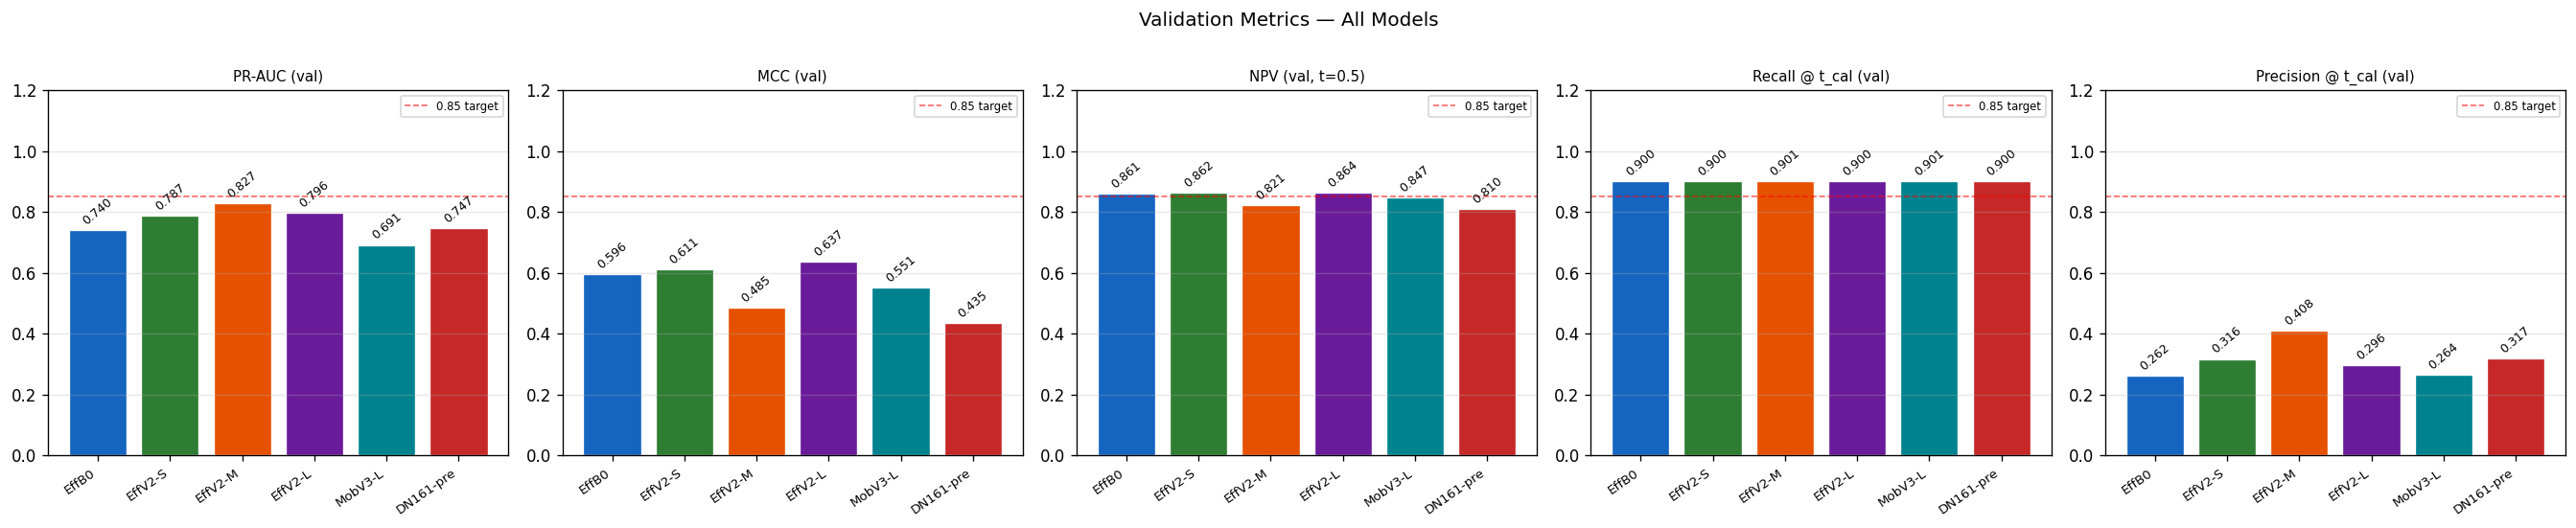

In [5]:
# ── METRICS BAR CHARTS ───────────────────────────────────────────────────────
metrics_spec = [
    ('val_prauc',    'PR-AUC (val)'),
    ('val_mcc',      'MCC (val)'),
    ('val_npv',      'NPV (val, t=0.5)'),
    ('recall_tcal',  'Recall @ t_cal (val)'),
    ('prec_tcal',    'Precision @ t_cal (val)'),
]

shorts = [MODEL_DATA[m['config']]['short'] for m in MODELS]
colors = [MODEL_DATA[m['config']]['color'] for m in MODELS]

fig, axes = plt.subplots(1, len(metrics_spec), figsize=(4.5 * len(metrics_spec), 4.5))
for ax, (key, label) in zip(axes, metrics_spec):
    vals = [MODEL_DATA[m['config']][key] for m in MODELS]
    bar_colors = [c if not np.isnan(v) else '#cccccc' for v, c in zip(vals, colors)]
    safe_vals  = [v if not np.isnan(v) else 0.0 for v in vals]
    bars = ax.bar(shorts, safe_vals, color=bar_colors, edgecolor='white', linewidth=0.8)
    for bar, val in zip(bars, vals):
        if not np.isnan(val):
            ax.text(
                bar.get_x() + bar.get_width() / 2, val + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=7.5, rotation=40,
            )
    ax.axhline(0.85, color='red', ls='--', lw=1, alpha=0.6, label='0.85 target')
    ax.set_ylim(0, 1.2)
    ax.set_title(label, fontsize=9)
    ax.set_xticklabels(shorts, rotation=35, ha='right', fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')
    ax.legend(fontsize=7)

fig.suptitle('Validation Metrics \u2014 All Models', fontsize=12, y=1.01)
fig.tight_layout()
plt.show()

---
## 2 · Validation PR & ROC Curves

C:\Users\jordi\AppData\Local\Temp\ipykernel_19828\1266893617.py:9: RuntimeWarning: overflow encountered in exp
  probs = 1 / (1 + np.exp(-logits))
C:\Users\jordi\AppData\Local\Temp\ipykernel_19828\1266893617.py:9: RuntimeWarning: overflow encountered in exp
  probs = 1 / (1 + np.exp(-logits))


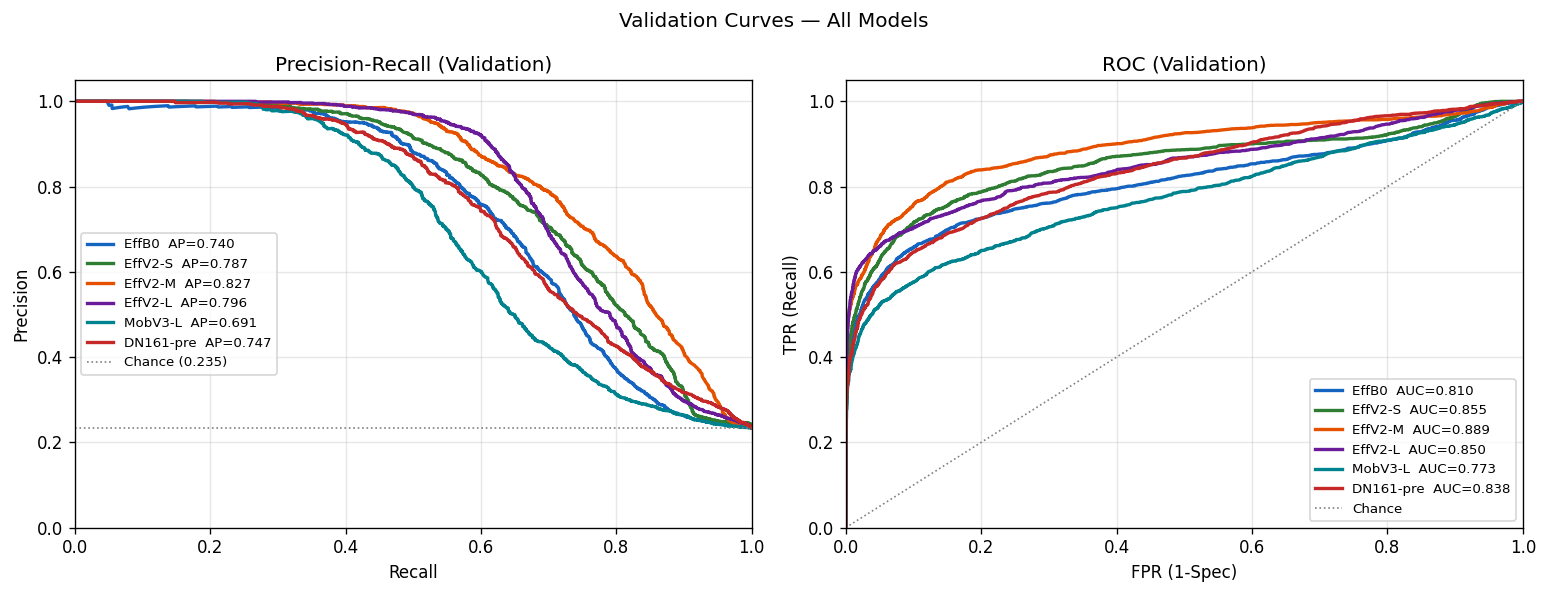

In [6]:
fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(13, 5))

chance_level = None
for m in MODELS:
    d = MODEL_DATA[m['config']]
    if d['val_preds'] is None:
        continue
    logits, labels_v, _ = d['val_preds']
    probs = 1 / (1 + np.exp(-logits))
    color = d['color']
    sname = d['short']

    prec, rec, _ = precision_recall_curve(labels_v, probs)
    ap            = average_precision_score(labels_v, probs)
    ax_pr.plot(rec, prec, color=color, lw=2, label=f'{sname}  AP={ap:.3f}')

    fpr, tpr, _ = roc_curve(labels_v, probs)
    roc_auc     = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, color=color, lw=2, label=f'{sname}  AUC={roc_auc:.3f}')

    if chance_level is None:
        chance_level = labels_v.mean()

if chance_level is not None:
    ax_pr.axhline(chance_level, color='grey', ls=':', lw=1, label=f'Chance ({chance_level:.3f})')
ax_roc.plot([0, 1], [0, 1], color='grey', ls=':', lw=1, label='Chance')

for ax, xlabel, ylabel, title in [
    (ax_pr,  'Recall',    'Precision', 'Precision-Recall (Validation)'),
    (ax_roc, 'FPR (1-Spec)', 'TPR (Recall)', 'ROC (Validation)'),
]:
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle('Validation Curves \u2014 All Models', fontsize=12)
fig.tight_layout()
plt.show()

---
## 3 · Subclass Recall \u2014 Validation

Recall broken down by suspicious subclass. This is the **primary metric** for clinical utility: each pathology class must be caught reliably.  
The 0.85 target line marks the per-class recall goal.

Two thresholds are shown:
- **t = 0.5** (default)
- **t_cal** (calibrated to achieve ≥ 90 % overall recall on validation)

In [7]:
# ── HELPER: subclass recall matrix ──────────────────────────────────────────
def build_recall_matrix(recall_key):
    """Returns (matrix, short_names) where missing values are 0.0."""
    mat, names = [], []
    for m in MODELS:
        d  = MODEL_DATA[m['config']]
        sr = d[recall_key]
        mat.append([sr.get(s, 0.0) for s in SUSPICIOUS_CLASSES])
        names.append(d['short'])
    return np.array(mat, dtype=float), names


def plot_recall_heatmap(mat, row_labels, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(len(SUSPICIOUS_CLASSES) * 1.6 + 1, len(row_labels) * 0.7 + 1))
        standalone = True
    else:
        fig = ax.get_figure()
        standalone = False

    im = ax.imshow(mat, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(SUSPICIOUS_CLASSES)))
    ax.set_xticklabels(SUSPICIOUS_CLASSES, rotation=30, ha='right', fontsize=9)
    ax.set_yticks(range(len(row_labels)))
    ax.set_yticklabels(row_labels, fontsize=9)
    for i in range(len(row_labels)):
        for j in range(len(SUSPICIOUS_CLASSES)):
            v = mat[i, j]
            txt = f'{v:.2f}' if v > 0 else '\u2014'
            color = 'white' if v < 0.35 else 'black'
            ax.text(j, i, txt, ha='center', va='center', fontsize=9, color=color,
                    fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.02, pad=0.02, label='Recall')
    ax.set_title(title, fontsize=10, pad=8)

    if standalone:
        fig.tight_layout()
        plt.show()


def plot_recall_grouped_bars(mat, row_labels, colors_list, title):
    n_models = len(row_labels)
    n_subs   = len(SUSPICIOUS_CLASSES)
    x        = np.arange(n_subs)
    width    = 0.8 / n_models

    fig, ax = plt.subplots(figsize=(n_subs * 1.5 + 1, 4.5))
    for i, (row, label, color) in enumerate(zip(mat, row_labels, colors_list)):
        offset = (i - n_models / 2 + 0.5) * width
        bars   = ax.bar(x + offset, row, width * 0.9, label=label, color=color, alpha=0.88)

    ax.axhline(0.85, color='red', ls='--', lw=1.5, alpha=0.7, label='0.85 target')
    ax.set_xticks(x)
    ax.set_xticklabels(SUSPICIOUS_CLASSES, rotation=20, ha='right', fontsize=9)
    ax.set_ylim(0, 1.15)
    ax.set_ylabel('Recall')
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
    ax.grid(True, alpha=0.3, axis='y')
    fig.tight_layout()
    plt.show()

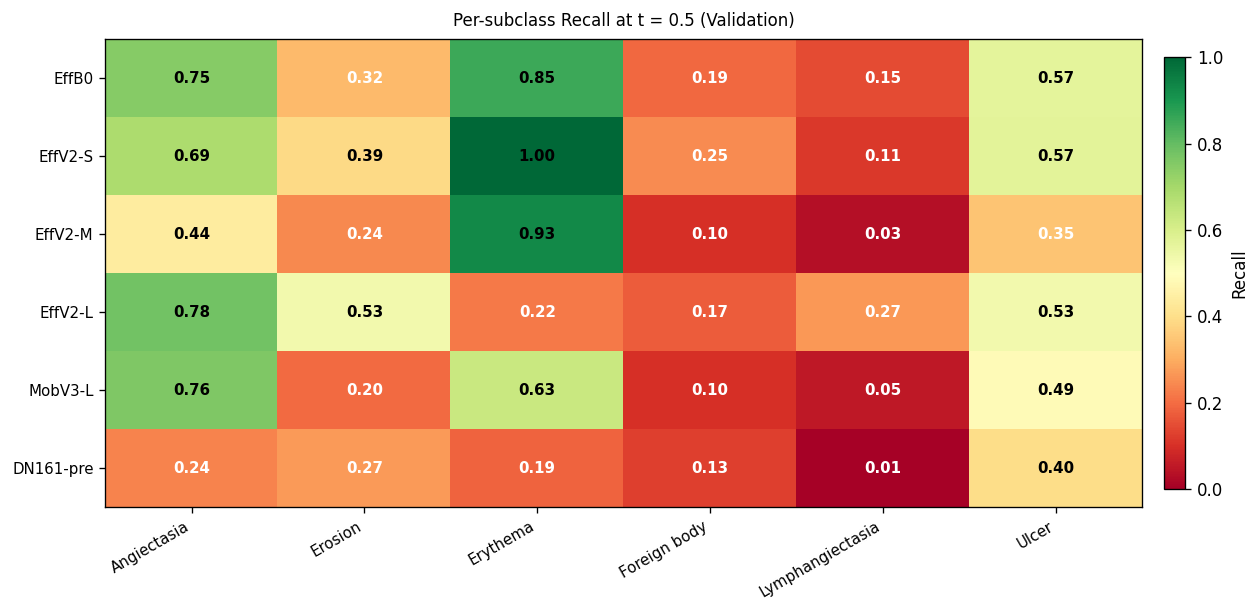

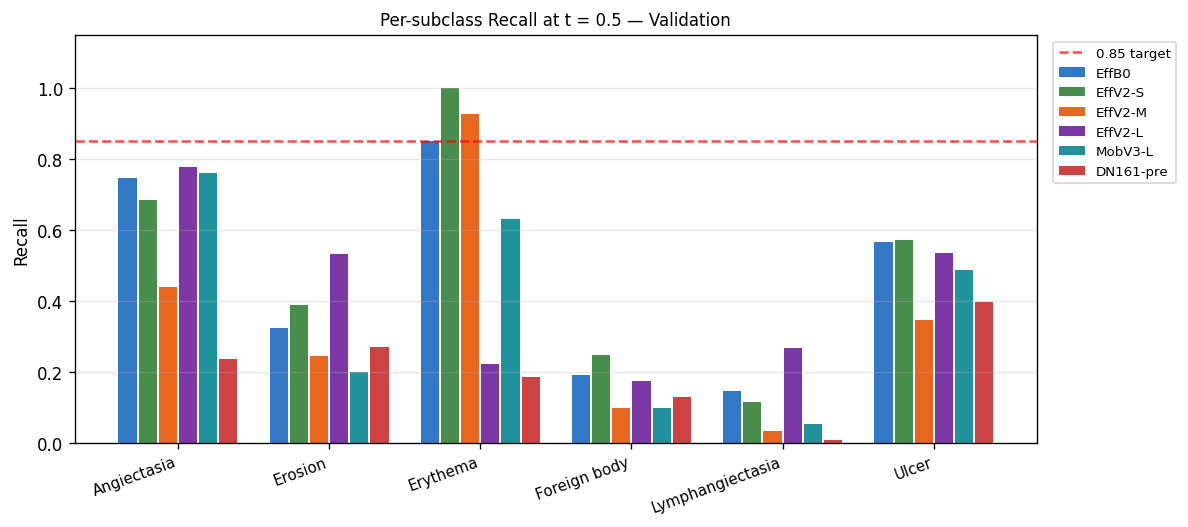

In [8]:
# ── SUBCLASS RECALL AT t = 0.5 ───────────────────────────────────────────────
mat05, short_names = build_recall_matrix('sub_r05')
colors_list        = [MODEL_DATA[m['config']]['color'] for m in MODELS]

plot_recall_heatmap(
    mat05, short_names,
    title='Per-subclass Recall at t = 0.5 (Validation)',
)
plot_recall_grouped_bars(
    mat05, short_names, colors_list,
    title='Per-subclass Recall at t = 0.5 \u2014 Validation',
)

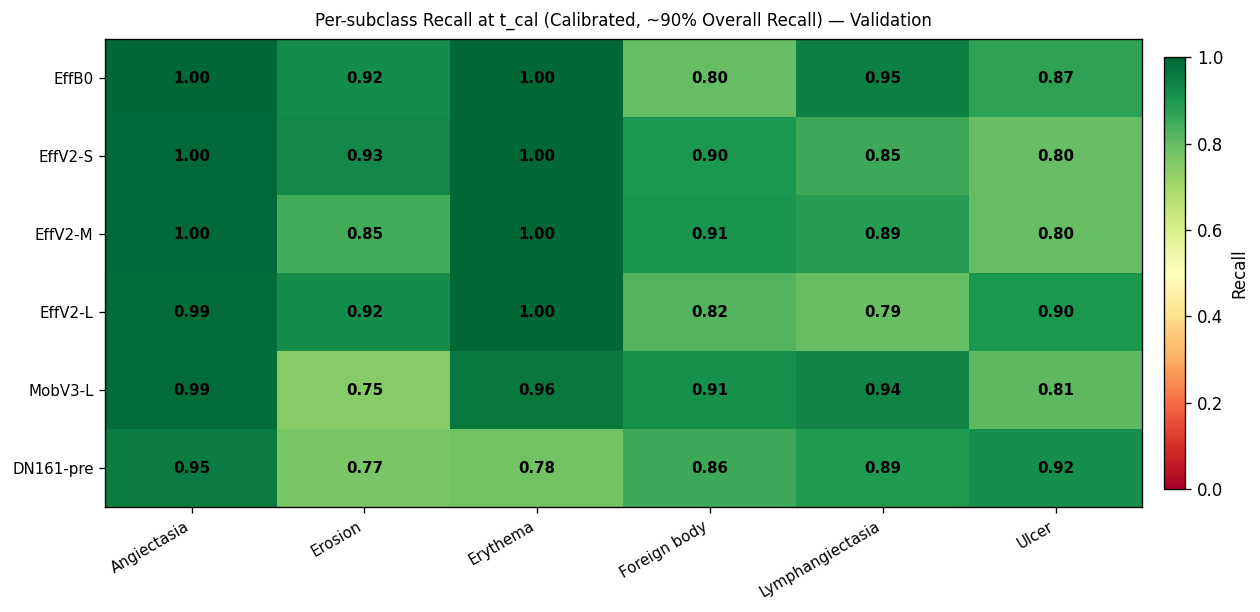

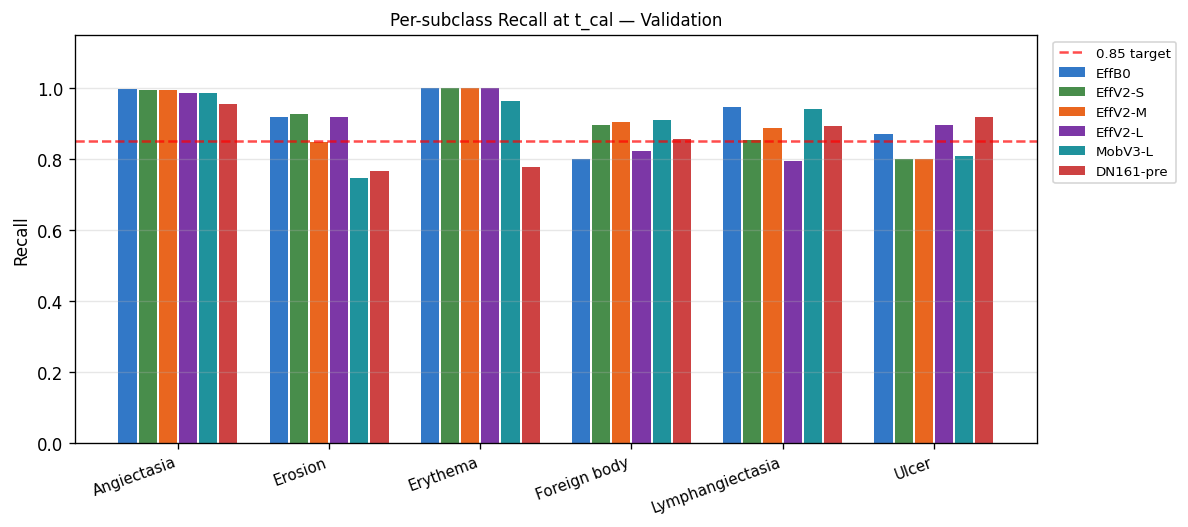

In [9]:
# ── SUBCLASS RECALL AT CALIBRATED THRESHOLD ──────────────────────────────────
matcal, _ = build_recall_matrix('sub_rcal')

plot_recall_heatmap(
    matcal, short_names,
    title='Per-subclass Recall at t_cal (Calibrated, ~90% Overall Recall) \u2014 Validation',
)
plot_recall_grouped_bars(
    matcal, short_names, colors_list,
    title='Per-subclass Recall at t_cal \u2014 Validation',
)

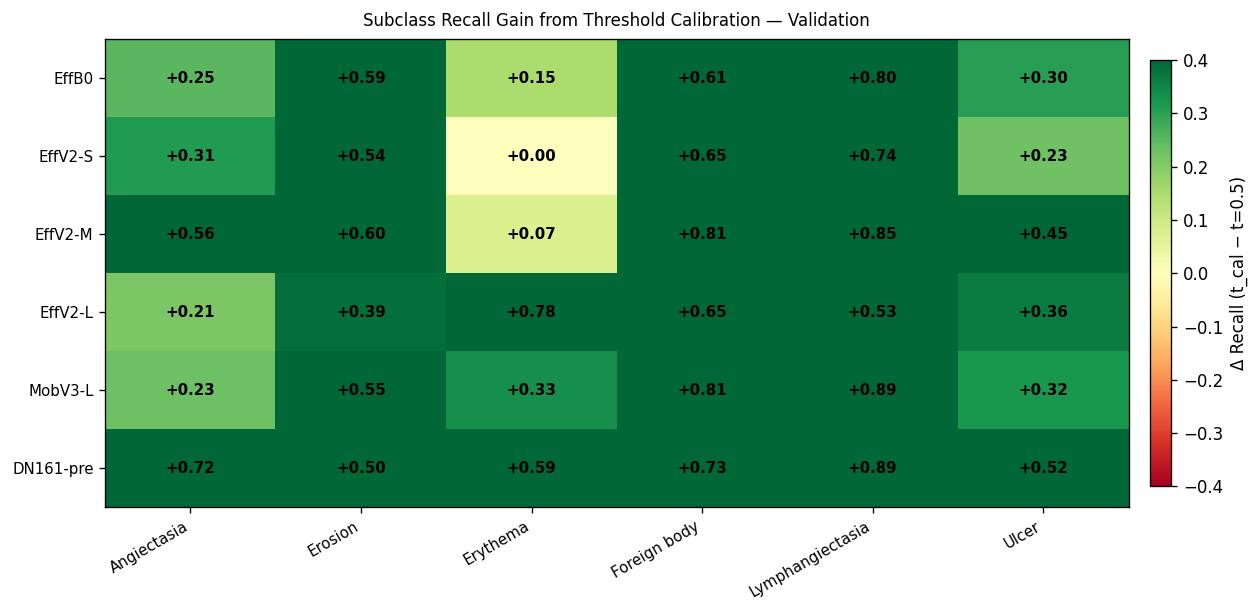

In [10]:
# ── DELTA: t_cal - t=0.5 (where recall gain comes from) ──────────────────────
delta = matcal - mat05

fig, ax = plt.subplots(figsize=(len(SUSPICIOUS_CLASSES) * 1.6 + 1, len(MODELS) * 0.7 + 1))
im = ax.imshow(delta, cmap='RdYlGn', vmin=-0.4, vmax=0.4, aspect='auto')
ax.set_xticks(range(len(SUSPICIOUS_CLASSES)))
ax.set_xticklabels(SUSPICIOUS_CLASSES, rotation=30, ha='right', fontsize=9)
ax.set_yticks(range(len(MODELS)))
ax.set_yticklabels(short_names, fontsize=9)
for i in range(len(MODELS)):
    for j in range(len(SUSPICIOUS_CLASSES)):
        v = delta[i, j]
        txt = f'{v:+.2f}' if (mat05[i, j] > 0 or matcal[i, j] > 0) else '\u2014'
        color = 'black'
        ax.text(j, i, txt, ha='center', va='center', fontsize=9, color=color, fontweight='bold')
plt.colorbar(im, ax=ax, fraction=0.02, pad=0.02, label='Δ Recall (t_cal \u2212 t=0.5)')
ax.set_title('Subclass Recall Gain from Threshold Calibration \u2014 Validation', fontsize=10, pad=8)
fig.tight_layout()
plt.show()

---
## 4 · Validation Confusion Matrices (at calibrated threshold)

One confusion matrix per trained model at *t_cal*.

C:\Users\jordi\AppData\Local\Temp\ipykernel_19828\4277995890.py:14: RuntimeWarning: overflow encountered in exp
  probs  = 1 / (1 + np.exp(-logits))
C:\Users\jordi\AppData\Local\Temp\ipykernel_19828\4277995890.py:14: RuntimeWarning: overflow encountered in exp
  probs  = 1 / (1 + np.exp(-logits))


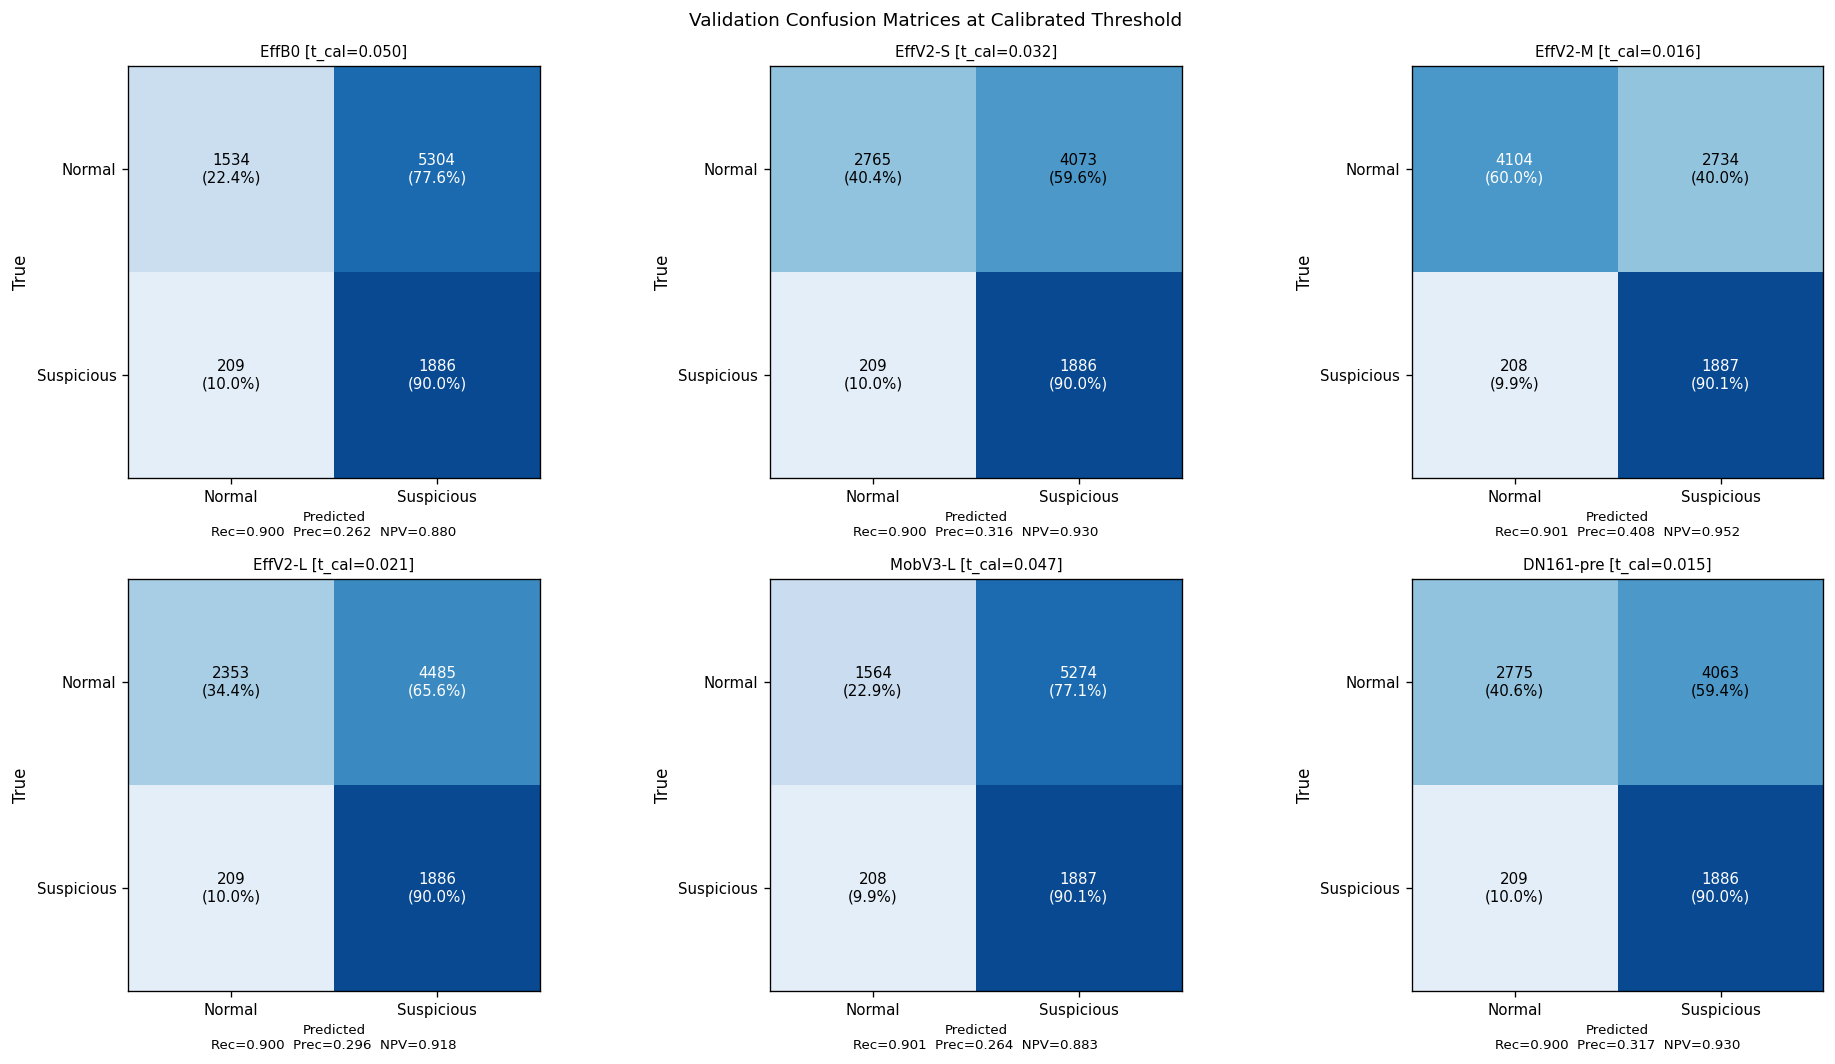

In [11]:
trained = [m for m in MODELS if MODEL_DATA[m['config']]['val_preds'] is not None]

if not trained:
    print('No trained models with validation predictions available.')
else:
    ncols = min(3, len(trained))
    nrows = (len(trained) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.5 * nrows), squeeze=False)
    axes_flat = axes.flatten()

    for ax, m in zip(axes_flat, trained):
        d      = MODEL_DATA[m['config']]
        logits, labels_v, _ = d['val_preds']
        probs  = 1 / (1 + np.exp(-logits))
        t      = d['threshold_cal'] if d['threshold_cal'] is not None else 0.5
        preds  = (probs >= t).astype(int)
        cm     = confusion_matrix(labels_v, preds)
        cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True)

        ax.imshow(cm_pct, vmin=0, vmax=1, cmap='Blues')
        tick_labels = ['Normal', 'Suspicious']
        ax.set_xticks([0, 1]); ax.set_xticklabels(tick_labels, fontsize=9)
        ax.set_yticks([0, 1]); ax.set_yticklabels(tick_labels, fontsize=9)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f'{cm[i,j]}\n({cm_pct[i,j]:.1%})',
                        ha='center', va='center', fontsize=9,
                        color='white' if cm_pct[i, j] > 0.6 else 'black')
        tp = cm[1,1]; fp = cm[0,1]; tn = cm[0,0]; fn = cm[1,0]
        rec_v  = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
        prec_v = tp / (tp + fp) if (tp + fp) > 0 else float('nan')
        npv_v  = tn / (tn + fn) if (tn + fn) > 0 else float('nan')
        t_str  = f't_cal={t:.3f}' if d['threshold_cal'] is not None else 't=0.5'
        ax.set_title(f'{d["short"]} [{t_str}]', fontsize=9)
        ax.set_ylabel('True')
        ax.set_xlabel(f'Predicted\nRec={rec_v:.3f}  Prec={prec_v:.3f}  NPV={npv_v:.3f}', fontsize=8)

    for ax in axes_flat[len(trained):]:
        ax.set_visible(False)

    fig.suptitle('Validation Confusion Matrices at Calibrated Threshold', fontsize=11)
    fig.tight_layout()
    plt.show()

---
## 5 · Test Set Comparison

> **Data-leakage note**: test metrics are shown here only for final reporting.  
> All model-selection and threshold-tuning decisions should be based on validation results above.

Generate test results with:
```
python scripts/evaluate_test.py outputs/runs/<model>_fold0_XXXX \
    --out outputs/test_evaluation/<model>_test_results.json
```

In [12]:
# ── TEST METRICS TABLE ───────────────────────────────────────────────────────
def _safe_div(a, b):
    return round(a / b, 4) if b > 0 else float('nan')


test_rows = []
for m in MODELS:
    d = MODEL_DATA[m['config']]
    t = d['test']
    na = '\u2014'
    if t is None:
        test_rows.append({
            'Model':        d['name'],
            'n_images':     na,
            'PR-AUC':       na,
            'MCC':          na,
            'NPV (t=0.5)':  na,
            'Recall@t_cal': na,
            'Prec@t_cal':   na,
        })
        continue
    m05  = t.get('metrics_at_0.5', {})
    mcal = t.get('metrics_at_calibrated_threshold') or {}
    tp05 = m05.get('tp', 0); fp05 = m05.get('fp', 0); fn05 = m05.get('fn', 0)
    test_rows.append({
        'Model':        d['name'],
        'n_images':     t.get('n_images', '?'),
        'PR-AUC':       round(_f(m05.get('pr_auc')), 4),
        'MCC':          round(_f(m05.get('mcc')),    4),
        'NPV (t=0.5)':  round(_f(m05.get('npv')),    4),
        'Recall@t_cal': round(_f(mcal.get('recall')),    4) if mcal else na,
        'Prec@t_cal':   round(_f(mcal.get('precision')), 4) if mcal else na,
    })

df_test = pd.DataFrame(test_rows).set_index('Model')
display(df_test)

,n_images,PR-AUC,MCC,NPV (t=0.5),Recall@t_cal,Prec@t_cal
Model,,,,,,
EfficientNet-B0,4995,0.5321,0.4691,0.9162,0.9094,0.1671
EfficientNet-V2-S,4995,0.6817,0.6154,0.9275,0.9770,0.1597
EfficientNet-V2-M,4995,0.6868,0.4858,0.8986,0.9223,0.2019
EfficientNet-V2-L,4995,0.5546,0.4519,0.9149,0.8863,0.1661
MobileNet-V3-Large,4995,0.5542,0.4918,0.9163,0.9496,0.1653
DenseNet-161 (pretrained),4995,0.5097,0.4004,0.8929,0.9669,0.1882


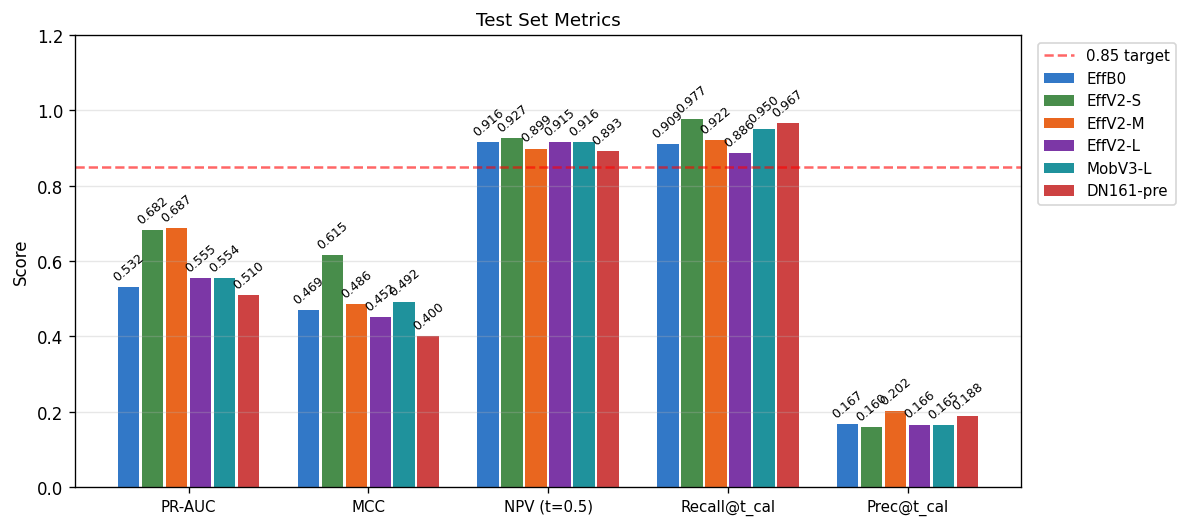

In [13]:
# ── TEST METRICS BAR CHART (models with data only) ───────────────────────────
test_available = [m for m in MODELS if MODEL_DATA[m['config']]['test'] is not None]

if not test_available:
    print('No test results available yet. Run evaluate_test.py for each model.')
else:
    t_metrics = [
        ('PR-AUC',      lambda t: _f(t.get('metrics_at_0.5', {}).get('pr_auc'))),
        ('MCC',         lambda t: _f(t.get('metrics_at_0.5', {}).get('mcc'))),
        ('NPV (t=0.5)', lambda t: _f(t.get('metrics_at_0.5', {}).get('npv'))),
        ('Recall@t_cal',lambda t: _f((t.get('metrics_at_calibrated_threshold') or {}).get('recall'))),
        ('Prec@t_cal',  lambda t: _f((t.get('metrics_at_calibrated_threshold') or {}).get('precision'))),
    ]

    n_avail  = len(test_available)
    n_met    = len(t_metrics)
    x        = np.arange(n_met)
    width    = 0.8 / max(n_avail, 1)

    fig, ax = plt.subplots(figsize=(n_met * 1.8 + 1, 4.5))
    for i, m in enumerate(test_available):
        d    = MODEL_DATA[m['config']]
        vals = [fn(d['test']) for _, fn in t_metrics]
        off  = (i - n_avail / 2 + 0.5) * width
        bars = ax.bar(x + off, [v if not np.isnan(v) else 0.0 for v in vals],
                      width * 0.9, label=d['short'], color=d['color'], alpha=0.88)
        for bar, val in zip(bars, vals):
            if not np.isnan(val):
                ax.text(bar.get_x() + bar.get_width() / 2, val + 0.01,
                        f'{val:.3f}', ha='center', va='bottom', fontsize=7.5, rotation=40)

    ax.axhline(0.85, color='red', ls='--', lw=1.5, alpha=0.6, label='0.85 target')
    ax.set_xticks(x)
    ax.set_xticklabels([lbl for lbl, _ in t_metrics], fontsize=9)
    ax.set_ylim(0, 1.2)
    ax.set_ylabel('Score')
    ax.set_title('Test Set Metrics', fontsize=11)
    ax.legend(fontsize=9, bbox_to_anchor=(1.01, 1), loc='upper left')
    ax.grid(True, alpha=0.3, axis='y')
    fig.tight_layout()
    plt.show()

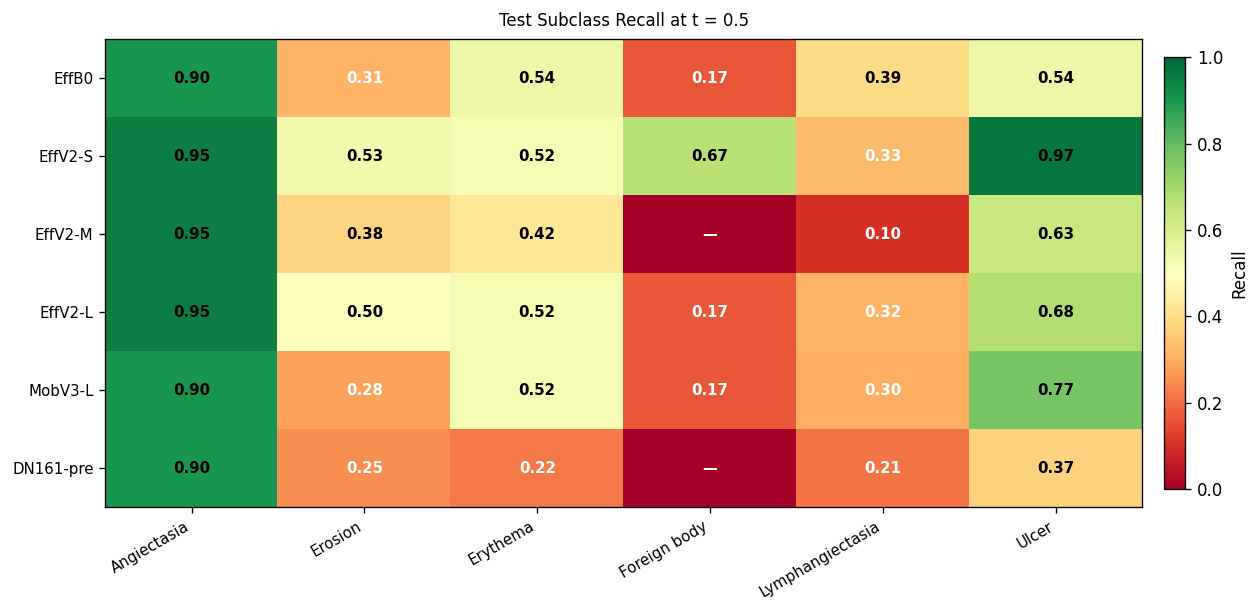

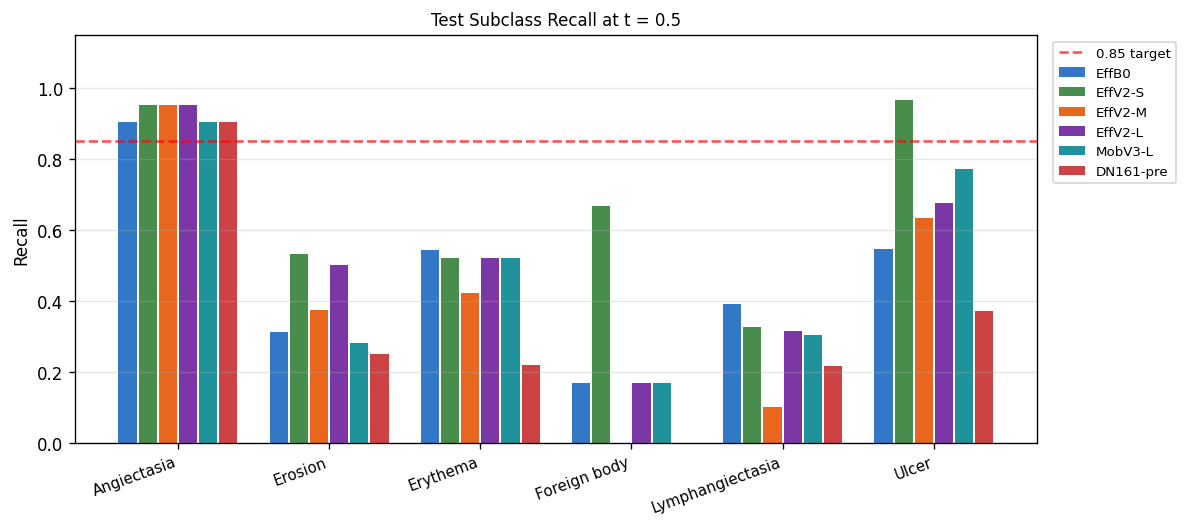

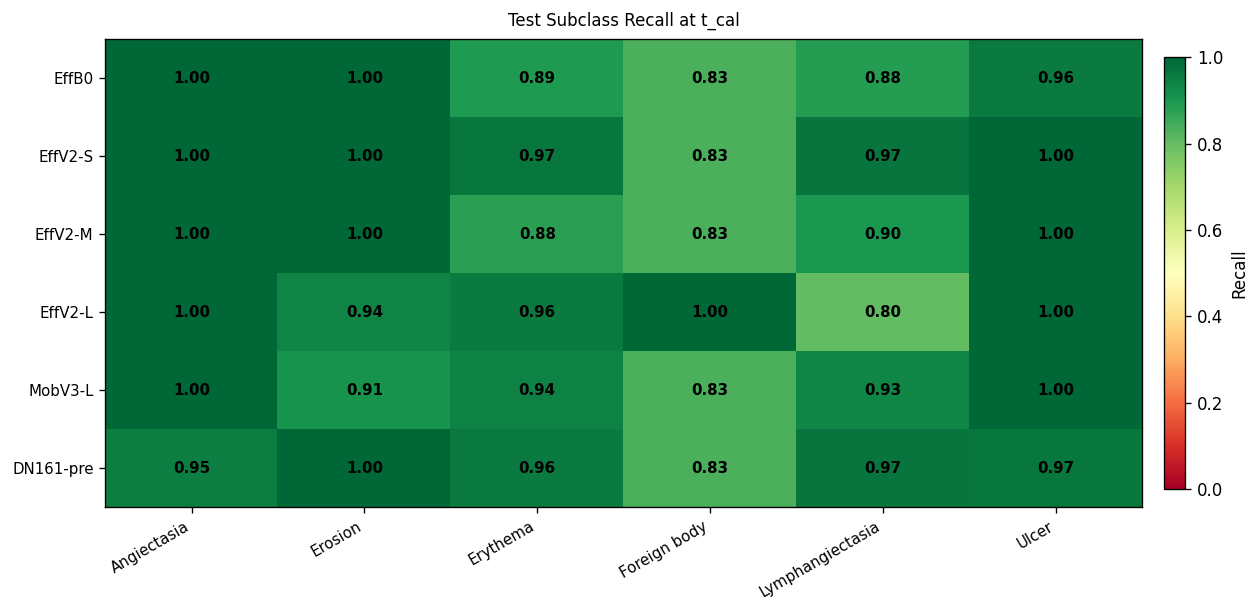

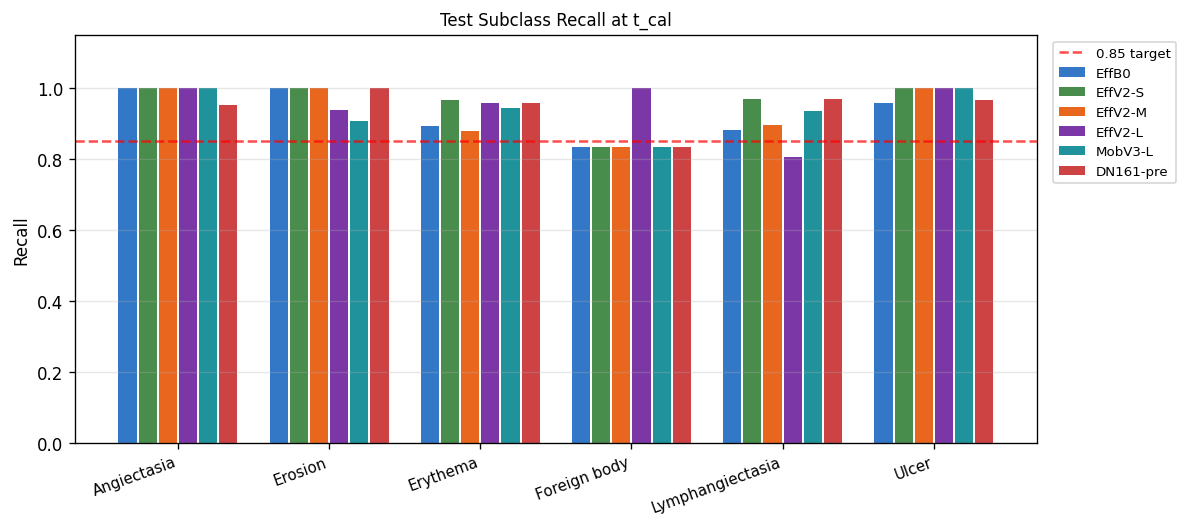

In [14]:
# ── TEST SUBCLASS RECALL ─────────────────────────────────────────────────────
if not test_available:
    print('No test results available.')
else:
    for threshold_key, json_key, title_suffix in [
        ('t=0.5',  'subclass_recall',                         'at t = 0.5'),
        ('t_cal',  'subclass_recall_at_calibrated_threshold', 'at t_cal'),
    ]:
        mat_t, names_t, colors_t = [], [], []
        for m in MODELS:
            d   = MODEL_DATA[m['config']]
            tst = d['test']
            sr  = (tst.get(json_key, {}) if tst else {})
            mat_t.append([sr.get(s, 0.0) for s in SUSPICIOUS_CLASSES])
            names_t.append(d['short'])
            colors_t.append(d['color'])

        mat_t = np.array(mat_t, dtype=float)
        plot_recall_heatmap(
            mat_t, names_t,
            title=f'Test Subclass Recall {title_suffix}',
        )
        plot_recall_grouped_bars(
            mat_t, names_t, colors_t,
            title=f'Test Subclass Recall {title_suffix}',
        )

---
## Test Confusion Matrices

Per-model confusion matrices on the held-out test split, using the calibrated threshold when it is available.

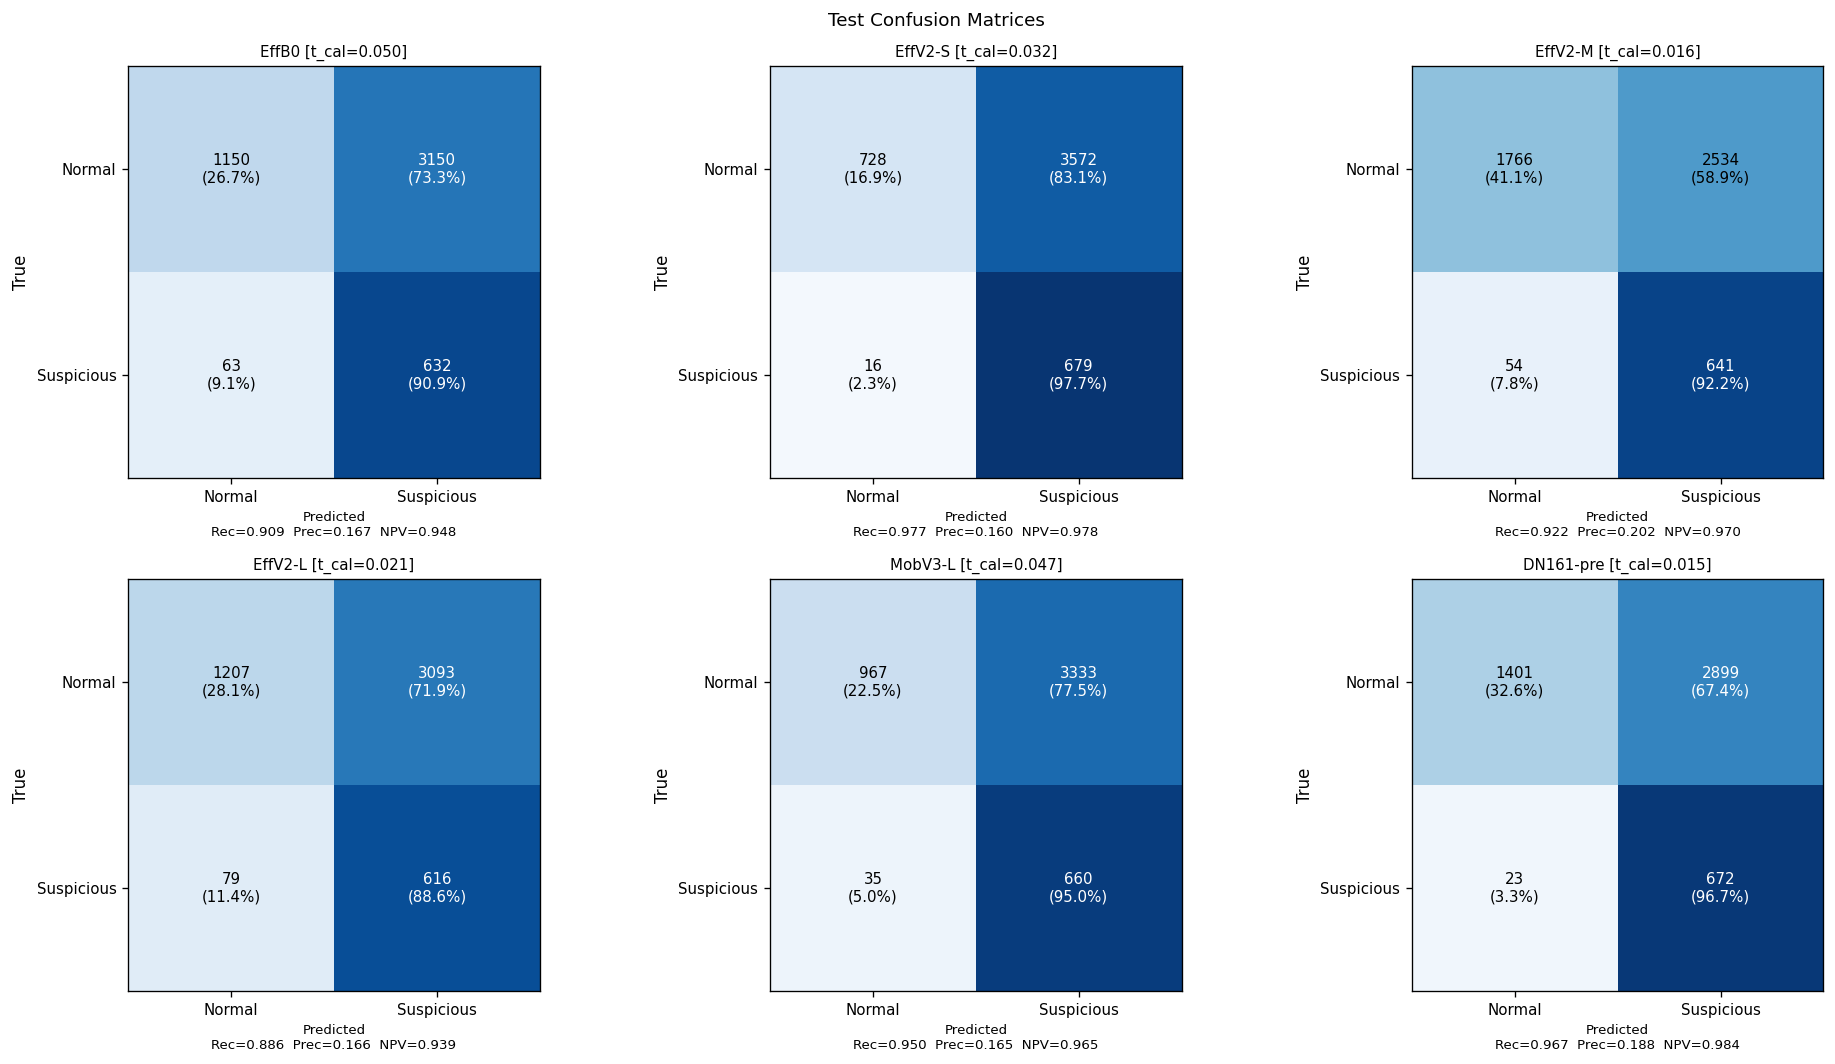

In [15]:
if not test_available:
    print('No test results available.')
else:
    ncols = min(3, len(test_available))
    nrows = (len(test_available) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.5 * nrows), squeeze=False)
    axes_flat = axes.flatten()

    for ax, m in zip(axes_flat, test_available):
        d = MODEL_DATA[m['config']]
        tst = d['test'] or {}
        cm_source = tst.get('metrics_at_calibrated_threshold') or tst.get('metrics_at_0.5') or {}

        tn = int(cm_source.get('tn', 0))
        fp = int(cm_source.get('fp', 0))
        fn = int(cm_source.get('fn', 0))
        tp = int(cm_source.get('tp', 0))

        cm = np.array([[tn, fp], [fn, tp]], dtype=float)
        cm_pct = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)

        ax.imshow(cm_pct, vmin=0, vmax=1, cmap='Blues')
        tick_labels = ['Normal', 'Suspicious']
        ax.set_xticks([0, 1]); ax.set_xticklabels(tick_labels, fontsize=9)
        ax.set_yticks([0, 1]); ax.set_yticklabels(tick_labels, fontsize=9)
        for i in range(2):
            for j in range(2):
                ax.text(
                    j, i, f'{int(cm[i, j])}\n({cm_pct[i, j]:.1%})',
                    ha='center', va='center', fontsize=9,
                    color='white' if cm_pct[i, j] > 0.6 else 'black'
                )

        rec_v = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
        prec_v = tp / (tp + fp) if (tp + fp) > 0 else float('nan')
        npv_v = tn / (tn + fn) if (tn + fn) > 0 else float('nan')
        if tst.get('metrics_at_calibrated_threshold'):
            t_str = f't_cal={tst["metrics_at_calibrated_threshold"].get("threshold", 0.5):.3f}'
        else:
            t_str = 't=0.5'
        ax.set_title(f'{d["short"]} [{t_str}]', fontsize=9)
        ax.set_ylabel('True')
        ax.set_xlabel(f'Predicted\nRec={rec_v:.3f}  Prec={prec_v:.3f}  NPV={npv_v:.3f}', fontsize=8)

    for ax in axes_flat[len(test_available):]:
        ax.set_visible(False)

    fig.suptitle('Test Confusion Matrices', fontsize=11)
    fig.tight_layout()
    plt.show()

---
## 6 · Validation vs. Test Delta

Gap between validation and test metrics — useful for detecting overfitting or distribution shift.

Val vs Test metric gap:


Val    Test  Δ (Test−Val)
Model                     Metric                              
EfficientNet-B0           PR-AUC  0.7403  0.5321       -0.2081
                          MCC     0.5963  0.4691       -0.1273
                          NPV     0.8609  0.9162        0.0553
EfficientNet-V2-S         PR-AUC  0.7873  0.6817       -0.1056
                          MCC     0.6111  0.6154        0.0043
                          NPV     0.8617  0.9275        0.0658
EfficientNet-V2-M         PR-AUC  0.8273  0.6868       -0.1405
                          MCC     0.4850  0.4858        0.0008
                          NPV     0.8208  0.8986        0.0779
EfficientNet-V2-L         PR-AUC  0.7961  0.5546       -0.2415
                          MCC     0.6373  0.4519       -0.1854
                          NPV     0.8639  0.9149        0.0509
MobileNet-V3-Large        PR-AUC  0.6912  0.5542       -0.1370
                          MCC     0.5509  0.4918       -0.0591
                          NPV     0.8475  0.9163        0.0688
DenseNet-161 (pretrained) PR-AUC  0.7471  0.5097       -0.2374
                          MCC     0.4346  0.4004       -0.0341
                          NPV     0.8101  0.8929        0.0828

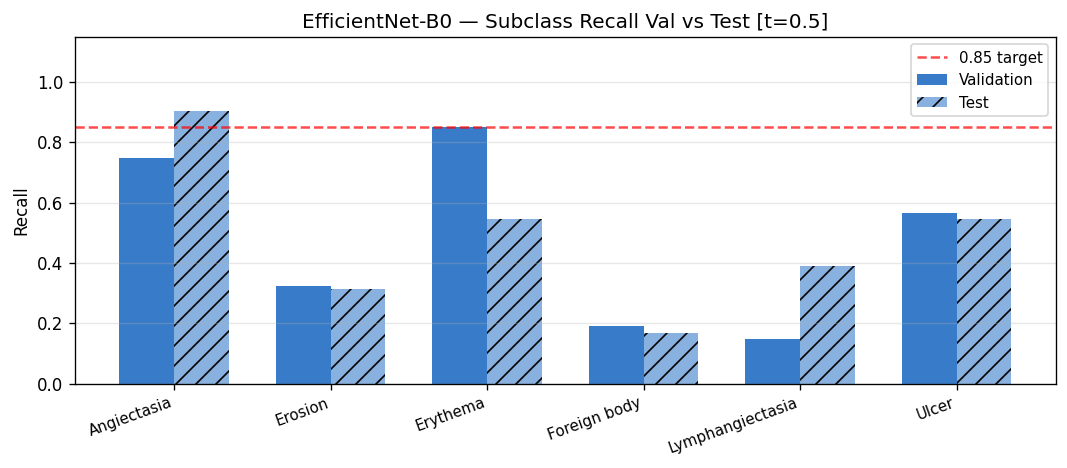

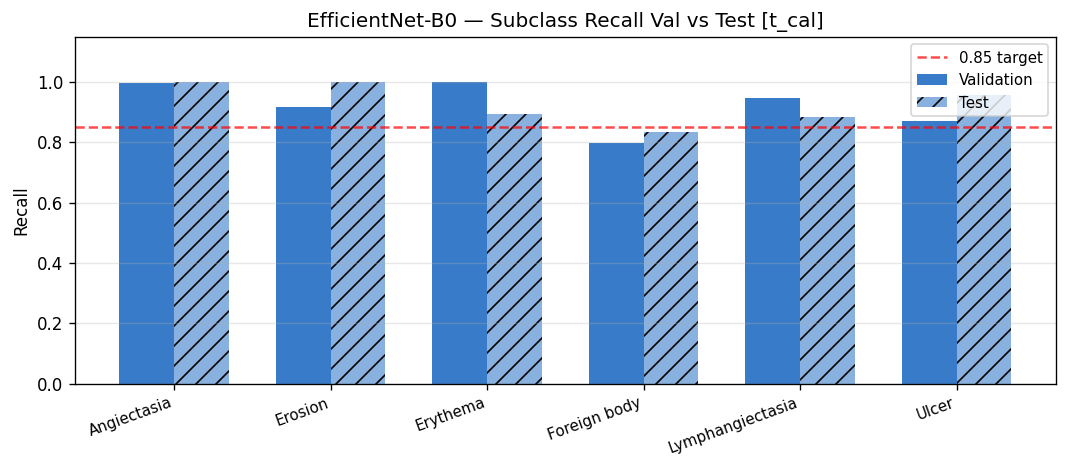

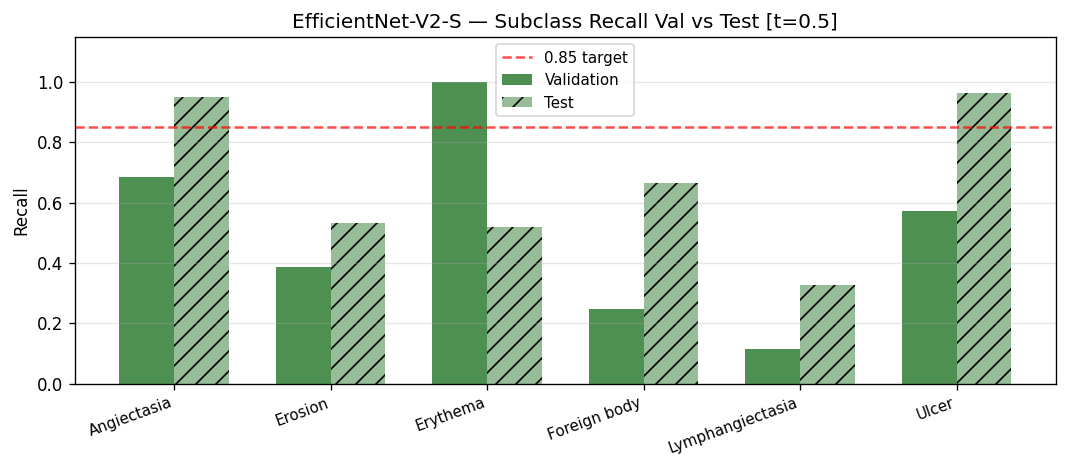

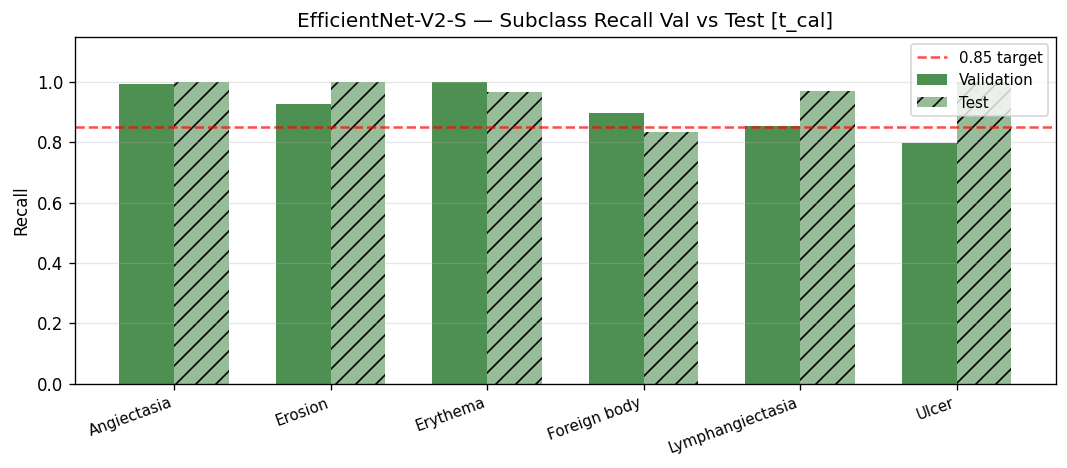

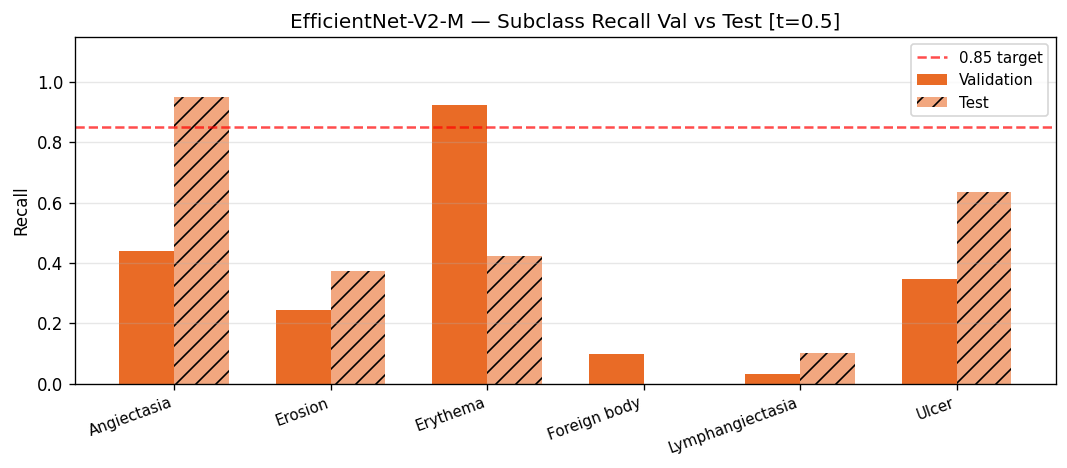

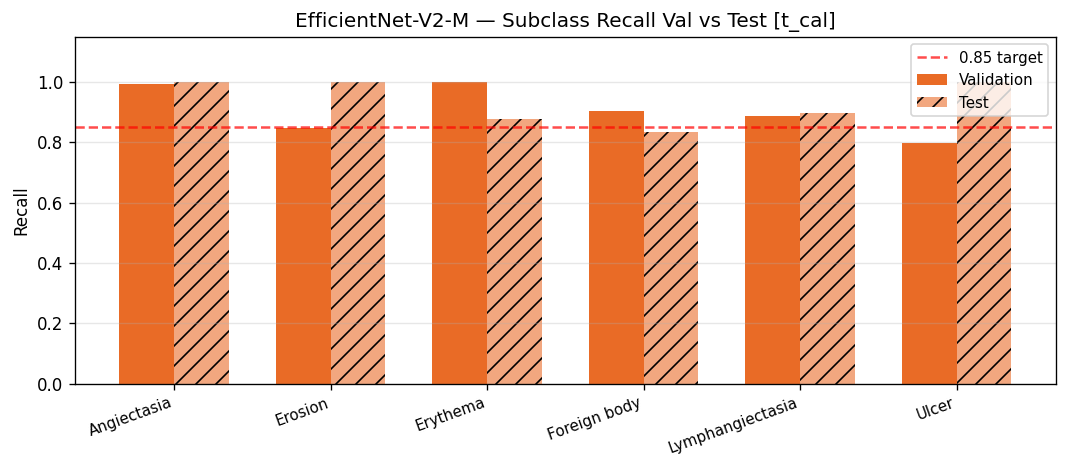

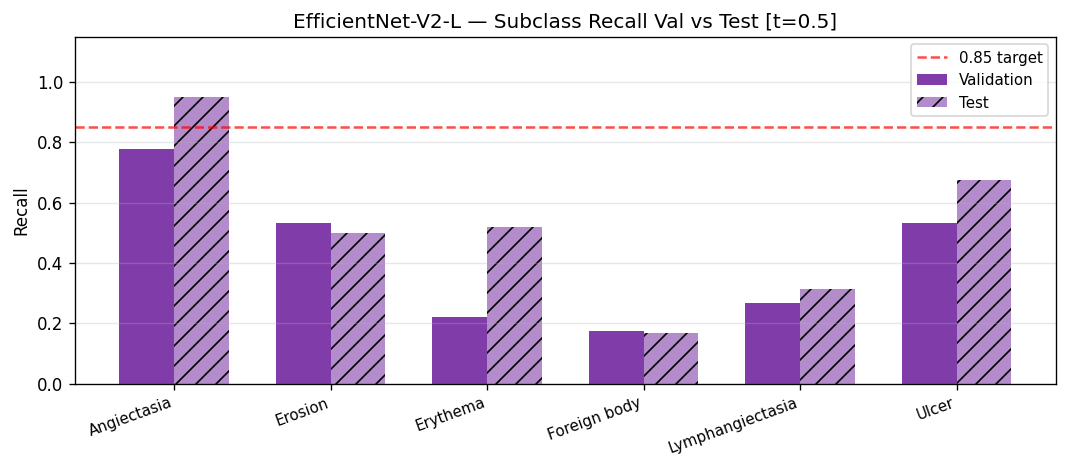

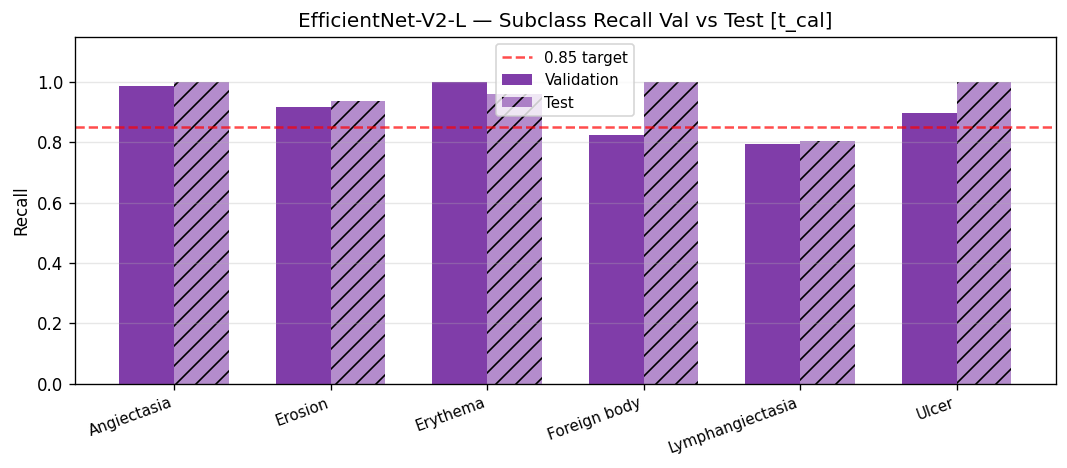

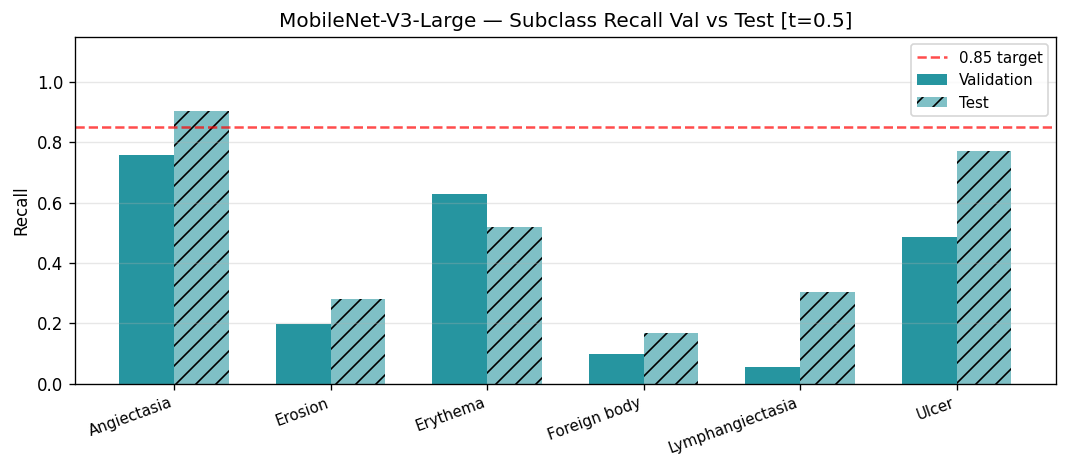

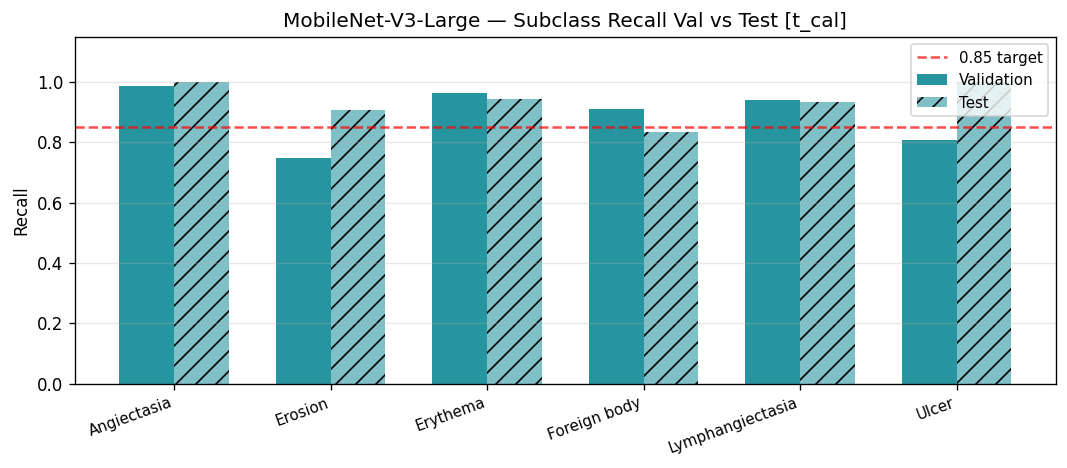

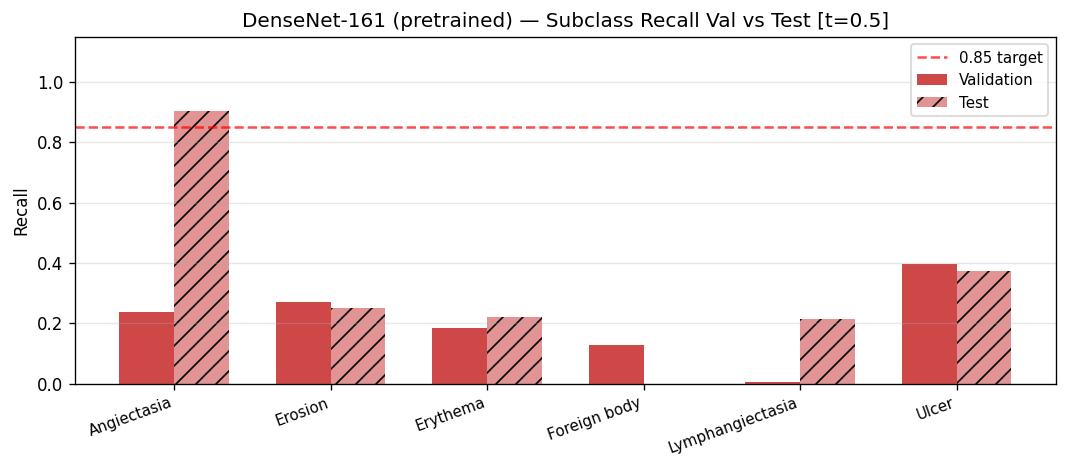

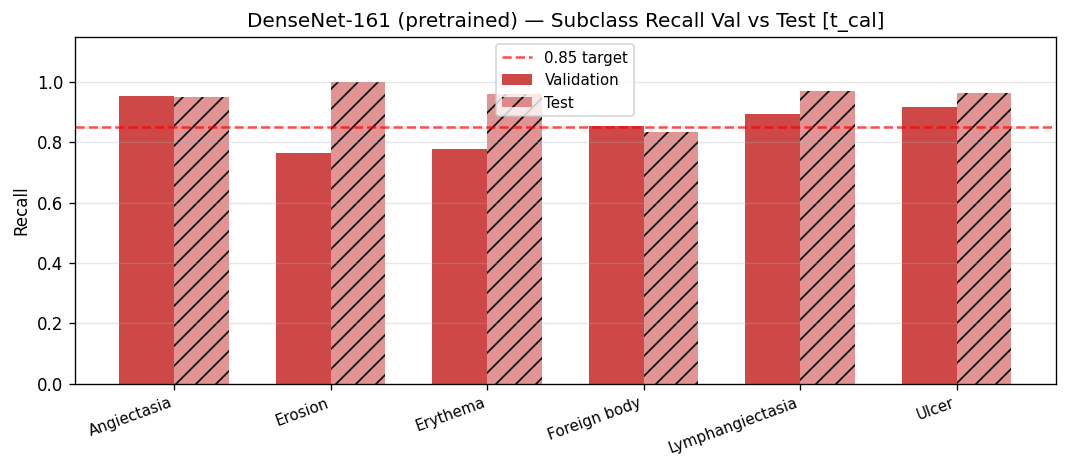

In [16]:
if not test_available:
    print('No test results available for comparison.')
else:
    delta_rows = []
    for m in test_available:
        d   = MODEL_DATA[m['config']]
        tst = d['test']
        m05 = tst.get('metrics_at_0.5', {})

        for metric, val_key, test_val in [
            ('PR-AUC', 'val_prauc',    _f(m05.get('pr_auc'))),
            ('MCC',    'val_mcc',      _f(m05.get('mcc'))),
            ('NPV',    'val_npv',      _f(m05.get('npv'))),
        ]:
            v_val = d[val_key]
            if not (np.isnan(v_val) or np.isnan(test_val)):
                delta_rows.append({
                    'Model':  d['name'],
                    'Metric': metric,
                    'Val':    round(v_val,    4),
                    'Test':   round(test_val, 4),
                    '\u0394 (Test\u2212Val)': round(test_val - v_val, 4),
                })

    if delta_rows:
        df_delta = pd.DataFrame(delta_rows).set_index(['Model', 'Metric'])
        print('Val vs Test metric gap:')
        display(df_delta)

    # Per-subclass recall: val (t=0.5) vs test (t=0.5)
    for m in test_available:
        d   = MODEL_DATA[m['config']]
        tst = d['test']

        for thresh_label, val_sub_key, test_sub_key in [
            ('t=0.5',  'sub_r05',  'subclass_recall'),
            ('t_cal',  'sub_rcal', 'subclass_recall_at_calibrated_threshold'),
        ]:
            val_sr  = d[val_sub_key]
            test_sr = tst.get(test_sub_key, {}) if tst else {}
            subs    = sorted(set(val_sr) | set(test_sr))
            if not subs:
                continue

            v_vals = [val_sr.get(s, 0.0)  for s in subs]
            t_vals = [test_sr.get(s, 0.0) for s in subs]
            x_pos  = np.arange(len(subs))
            w      = 0.35

            fig, ax = plt.subplots(figsize=(max(6, len(subs) * 1.5), 4))
            ax.bar(x_pos - w/2, v_vals, w, label='Validation', color=d['color'], alpha=0.85)
            ax.bar(x_pos + w/2, t_vals, w, label='Test',
                   color=d['color'], alpha=0.50, hatch='//')
            ax.set_xticks(x_pos)
            ax.set_xticklabels(subs, rotation=20, ha='right', fontsize=9)
            ax.set_ylim(0, 1.15)
            ax.set_ylabel('Recall')
            ax.axhline(0.85, color='red', ls='--', lw=1.5, alpha=0.7, label='0.85 target')
            ax.legend(fontsize=9)
            ax.grid(True, alpha=0.3, axis='y')
            ax.set_title(f'{d["name"]} \u2014 Subclass Recall Val vs Test [{thresh_label}]')
            fig.tight_layout()
            plt.show()